# TP — Clasificación de texto con Multilayer Perceptron
### Redes Neuronales / Deep Learning

Dataset: **20 Newsgroups**, con documentos pertenecientes a 20 categorías.

## Objetivos

- Implementar un MLP configurable con una, dos o tres capas ocultas.
- Explorar distintas cantidades de neuronas y funciones de activación.
- Comparar Adam, RMSprop y SGD, incluyendo sus parámetros de momentos.
- Buscar hiperparámetros de preprocesamiento y entrenamiento mediante Optuna.
- Aplicar pruning para interrumpir pruebas poco prometedoras.
- Analizar el desempeño, los tiempos de entrenamiento y el sobreajuste.
- Comparar el MLP seleccionado con regresión Softmax.

## 0. Setup

In [ ]:
!pip install -q mlflow optuna


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 512.5 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 76.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 64.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)


Usando dispositivo: cpu


In [ ]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

## 1. Datos: 20 Newsgroups

Se utiliza `remove=('headers', 'footers', 'quotes')` para quitar encabezados, firmas y citas que podrían facilitar la clasificación por información ajena al cuerpo del mensaje. El conjunto oficial de test se reserva para la evaluación final.

In [ ]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


## 2. Preprocesamiento configurable

La función de preprocesamiento incluye estos hiperparámetros, que luego se exploran con Optuna:

- `remove_stopwords` (`True`/`False`): sacar palabras muy frecuentes y poco informativas (`the`, `is`, `and`, ...).
- `normalization` (`"none"` / `"stem"` / `"lemmatize"`):
  - `"none"`: no se normaliza la palabra.
  - `"stem"`: **stemming** con Porter Stemmer — corta la palabra a una raíz heurística (`"running"` → `"run"`, a veces resultados no son palabras reales: `"studies"` → `"studi"`).
  - `"lemmatize"`: **lematización** con WordNet, usando la categoría gramatical por defecto (sustantivos). Por ejemplo, `"engines"` pasa a `"engine"`, pero `"running"` permanece igual. Esta implementación no identifica automáticamente la categoría gramatical de cada palabra.

### Implementación de `preprocess_text`

Pasos implementados:
1. Tokenizar el texto con `word_tokenize`.
2. Pasar todo a minúsculas y quedarse solo con tokens alfabéticos (`token.isalpha()`), para descartar números y puntuación.
3. Si `remove_stopwords` es `True`, sacar los tokens que estén en el set de stopwords.
4. Según `normalization`, aplicar `stemmer.stem(token)`, `lemmatizer.lemmatize(token)`, o dejar el token igual.
5. Devolver los tokens unidos con espacios (un string, para poder pasárselo después a `TfidfVectorizer`).

In [6]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()
def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # Eliminación opcional de stopwords
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # Normalización opcional de los tokens
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens)

In [ ]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


### Explicación del código de preprocesamiento

La función `preprocess_text` recibe un texto y dos parámetros configurables: `remove_stopwords` y `normalization`.

Primero se utiliza `word_tokenize` de NLTK para separar el texto en tokens. Luego se convierten los tokens a minúsculas y se conservan solamente aquellos que contienen caracteres alfabéticos mediante `isalpha()`.

Si `remove_stopwords` es verdadero, se eliminan las palabras pertenecientes al conjunto de stopwords en inglés.

Finalmente, según el valor de `normalization`, se aplica stemming mediante `PorterStemmer`, lematización mediante `WordNetLemmatizer` o no se realiza ninguna normalización.

La salida es un único string con los tokens separados por espacios, que luego puede ser procesado por `TfidfVectorizer`.



## 3. Vectorización TF-IDF

Los textos preprocesados se convierten en vectores numéricos con `TfidfVectorizer`. Se controlan:

- `ngram_range`: `(1, 1)` para unigramas o `(1, 2)` para unigramas y bigramas.
- `max_features`: cantidad máxima de términos del vocabulario.
- `min_df`: cantidad mínima de documentos en los que debe aparecer un término.

El vectorizador se ajusta solamente con los documentos de entrenamiento y se usa para transformar validación o test, según la etapa del experimento.

In [7]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    # Ajuste del vocabulario e IDF solamente con entrenamiento.
    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df,
        norm='l2'
    )
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

In [ ]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])


Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


### Explicación del código de vectorización

La función `vectorize_data` transforma los textos en representaciones numéricas mediante `TfidfVectorizer` de `scikit-learn`.

El vectorizador se ajusta únicamente sobre `train_texts` utilizando `fit_transform`. Luego se utiliza el mismo vectorizador para transformar `test_texts`.

Esto es importante porque el vocabulario y los valores de IDF se obtienen solamente a partir del conjunto de entrenamiento, evitando utilizar información del conjunto de prueba durante el ajuste del vectorizador.

Los hiperparámetros `ngram_range`, `max_features` y `min_df` permiten controlar el vocabulario utilizado por el modelo.

Además, se utiliza `norm='l2'` en `TfidfVectorizer`. Esto hace que cada vector TF-IDF quede normalizado en norma L2, controlando su magnitud y haciendo que la representación no dependa directamente de la longitud del documento.


## 4. Modelos: MLP y referencia Softmax

El modelo principal es un MLP configurable con una, dos o tres capas ocultas. Cada capa oculta combina una transformación lineal con una activación ReLU, Tanh o Sigmoid. La capa de salida genera un logit para cada una de las 20 categorías.

Como referencia se define `SoftmaxRegression`, que utiliza una única capa lineal y no tiene capas ocultas.

Ambos modelos devuelven logits sin aplicar Softmax: `CrossEntropyLoss` realiza internamente la operación equivalente a `log_softmax` seguida de `NLLLoss`.

Las pruebas con entradas aleatorias comprueban las dimensiones de salida; no evalúan la capacidad de clasificación.

In [ ]:
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        # Capa lineal de referencia, sin capas ocultas
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        # Salida de logits, sin aplicar Softmax
        return self.linear(x)

In [8]:
class MLP(nn.Module):
    def __init__(
        self,
        input_dim,
        num_classes,
        hidden_dims=(128,),
        activation="relu"
    ):
        super().__init__()

        activaciones = {
            "relu": nn.ReLU,
            "tanh": nn.Tanh,
            "sigmoid": nn.Sigmoid
        }

        if not 1 <= len(hidden_dims) <= 3:
            raise ValueError("Debe haber entre 1 y 3 capas ocultas.")

        if activation not in activaciones:
            raise ValueError("La activación debe ser relu, tanh o sigmoid.")

        capas = []
        dimension_anterior = input_dim

        for neuronas in hidden_dims:
            capas.append(nn.Linear(dimension_anterior, neuronas))
            capas.append(activaciones[activation]())
            dimension_anterior = neuronas

        capas.append(nn.Linear(dimension_anterior, num_classes))

        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)

In [ ]:
modelo_prueba_configurable = MLP(
    input_dim=2000,
    num_classes=20,
    hidden_dims=(128, 64),
    activation="tanh"
)

print(modelo_prueba_configurable)

salida = modelo_prueba_configurable(torch.randn(4, 2000))
print("Forma de salida:", salida.shape)

MLP(
  (red): Sequential(
    (0): Linear(in_features=2000, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=20, bias=True)
  )
)
Forma de salida: torch.Size([4, 20])


In [ ]:
# Sanity check
_dummy = torch.randn(4, 50)
_model_check = SoftmaxRegression(input_dim=50, num_classes=20)
_out = _model_check(_dummy)
assert _out is not None and _out.shape == (4, 20), "Revisá SoftmaxRegression"
print("Shape de salida OK:", _out.shape)


Shape de salida OK: torch.Size([4, 20])


## 5. Entrenamiento y pruebas iniciales

Las matrices TF-IDF se convierten a tensores densos para utilizarlas con `DataLoader`. La misma función de entrenamiento sirve para MLP y Softmax, aunque conserva el nombre `train_softmax_model` del trabajo anterior.

La función registra pérdida y accuracy por época en MLflow. También admite un `writer` opcional para TensorBoard, pero en los experimentos de esta notebook no se proporciona uno. No se guardan modelos entrenados en MLflow en esta versión.

Primero se realizan pruebas de cinco épocas con una configuración de preprocesamiento fija. Después se exploran arquitectura, optimización y preprocesamiento mediante Optuna.

In [9]:
# Separación del conjunto de entrenamiento en train y validación
textos_train, textos_val, y_train, y_val = train_test_split(
    newsgroups_train.data,
    newsgroups_train.target,
    test_size=0.2,
    random_state=SEED,
    stratify=newsgroups_train.target
)

# Preprocesamiento con una configuración inicial fija
textos_train_proc = [
    preprocess_text(texto, remove_stopwords=True, normalization="none")
    for texto in textos_train
]

textos_val_proc = [
    preprocess_text(texto, remove_stopwords=True, normalization="none")
    for texto in textos_val
]

# El vocabulario y los valores de IDF se ajustan solamente con train
X_train, X_val, vectorizador = vectorize_data(
    textos_train_proc,
    textos_val_proc,
    ngram_range=(1, 1),
    max_features=2000,
    min_df=2
)

print("Forma de train:", X_train.shape)
print("Forma de validación:", X_val.shape)

Forma de train: (9051, 2000)
Forma de validación: (2263, 2000)


In [10]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)

def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="softmax", trial=None):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
              f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
              f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        mlflow.log_metric("train_acc", train_acc, step=epoch)
        mlflow.log_metric("val_acc", val_acc, step=epoch)
        # Comunicación del resultado intermedio a Optuna
        if trial is not None:
            trial.report(val_acc, step=epoch)

            # Interrupción si Optuna decide descartar esta prueba
            if trial.should_prune():
                raise optuna.TrialPruned()

    return history

### Conversión a tensores y cálculo de métricas

`to_tensor_dataset` convierte la matriz dispersa TF-IDF a un tensor denso `float32` y las etiquetas a un tensor `long`, compatible con `CrossEntropyLoss`.

En cada batch se calculan los logits y la pérdida, se ejecuta `loss.backward()` y se actualizan los pesos con `optimizer.step()`.

Las métricas de entrenamiento se acumulan durante los batches, mientras los pesos cambian. Por lo tanto, representan el desempeño a lo largo de la época, no una evaluación adicional del modelo con sus pesos finales sobre todo train.

La validación se realiza después de cada época con `model.eval()` y `torch.no_grad()`, sin actualizar los pesos. Sus métricas se usan para elegir la configuración y la cantidad de épocas, mientras que test se reserva para la evaluación final.

In [ ]:
# Conversión de los datos a tensores de PyTorch
dataset_train = to_tensor_dataset(X_train, y_train)
dataset_val = to_tensor_dataset(X_val, y_val)

# Organización de los documentos en batches
train_loader = DataLoader(
    dataset_train,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    dataset_val,
    batch_size=64,
    shuffle=False
)

# Inspección de un batch de entrenamiento
documentos, etiquetas = next(iter(train_loader))

print("Forma de los documentos:", documentos.shape)
print("Forma de las etiquetas:", etiquetas.shape)

Forma de los documentos: torch.Size([64, 2000])
Forma de las etiquetas: torch.Size([64])


In [ ]:
# Inicialización para que la prueba se pueda reproducir
torch.manual_seed(SEED)

# Creación del MLP y traslado al dispositivo disponible
modelo_mlp = MLP(
    input_dim=X_train.shape[1],
    num_classes=NUM_CLASSES
).to(device)

# Configuración del optimizador
optimizador = optim.Adam(
    modelo_mlp.parameters(),
    lr=0.001
)

# Entrenamiento y registro de resultados
with mlflow.start_run(run_name="mlp_inicial"):
    historial_mlp = train_softmax_model(
        model=modelo_mlp,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizador,
        epochs=5,
        run_name="mlp_inicial"
    )

2026/10/21 15:13:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/21 15:13:01 INFO mlflow.store.db.utils: Updating database tables


[mlp_inicial] Epoch 1/5 - train_loss: 2.7578 train_acc: 0.3613 - val_loss: 2.2986 val_acc: 0.5312
[mlp_inicial] Epoch 2/5 - train_loss: 1.8156 train_acc: 0.6208 - val_loss: 1.5775 val_acc: 0.6142
[mlp_inicial] Epoch 3/5 - train_loss: 1.2707 train_acc: 0.6995 - val_loss: 1.3327 val_acc: 0.6310
[mlp_inicial] Epoch 4/5 - train_loss: 1.0131 train_acc: 0.7477 - val_loss: 1.2366 val_acc: 0.6315
[mlp_inicial] Epoch 5/5 - train_loss: 0.8513 train_acc: 0.7812 - val_loss: 1.2058 val_acc: 0.6319


- Accuracy: cuenta cuántas categorías predijo correctamente.
- Pérdida: también tiene en cuenta qué tan confiado estuvo al predecir. Puede mejorar aunque no cambie la categoría elegida.

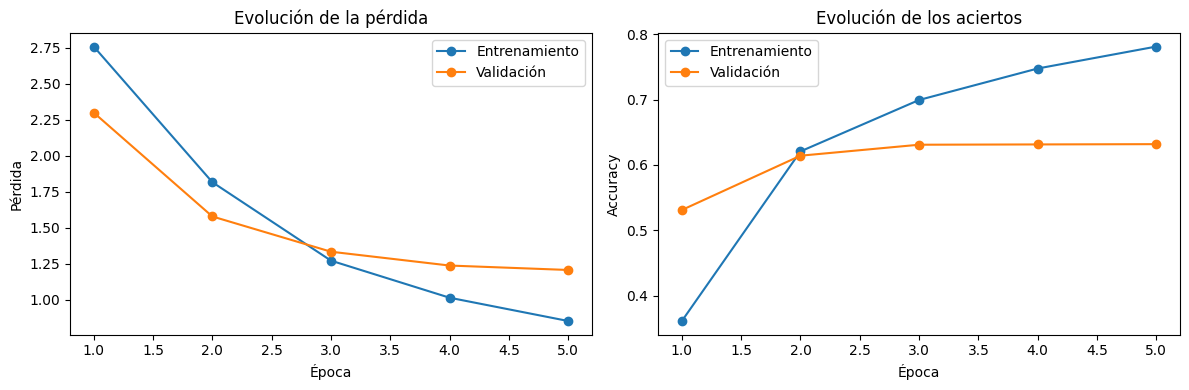

In [ ]:
epocas = range(1, len(historial_mlp["train_loss"]) + 1)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].plot(epocas, historial_mlp["train_loss"], marker="o",
             label="Entrenamiento")
ejes[0].plot(epocas, historial_mlp["val_loss"], marker="o",
             label="Validación")
ejes[0].set_title("Evolución de la pérdida")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Pérdida")
ejes[0].legend()

ejes[1].plot(epocas, historial_mlp["train_acc"], marker="o",
             label="Entrenamiento")
ejes[1].plot(epocas, historial_mlp["val_acc"], marker="o",
             label="Validación")
ejes[1].set_title("Evolución de los aciertos")
ejes[1].set_xlabel("Época")
ejes[1].set_ylabel("Accuracy")
ejes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
torch.manual_seed(SEED)

modelo_mlp_2 = MLP(
    input_dim=X_train.shape[1],
    num_classes=NUM_CLASSES,
    hidden_dims=(128, 64),
    activation="tanh"
).to(device)

optimizador_2 = optim.Adam(
    modelo_mlp_2.parameters(),
    lr=0.001
)

with mlflow.start_run(run_name="mlp_dos_capas_tanh"):
    historial_mlp_2 = train_softmax_model(
        model=modelo_mlp_2,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizador_2,
        epochs=5,
        run_name="mlp_dos_capas_tanh"
    )

[mlp_dos_capas_tanh] Epoch 1/5 - train_loss: 2.4897 train_acc: 0.2947 - val_loss: 1.7657 val_acc: 0.4954
[mlp_dos_capas_tanh] Epoch 2/5 - train_loss: 1.3894 train_acc: 0.6011 - val_loss: 1.3560 val_acc: 0.5957
[mlp_dos_capas_tanh] Epoch 3/5 - train_loss: 1.0152 train_acc: 0.7038 - val_loss: 1.2881 val_acc: 0.6191
[mlp_dos_capas_tanh] Epoch 4/5 - train_loss: 0.8181 train_acc: 0.7601 - val_loss: 1.3044 val_acc: 0.6116
[mlp_dos_capas_tanh] Epoch 5/5 - train_loss: 0.6792 train_acc: 0.8070 - val_loss: 1.3483 val_acc: 0.6080


In [ ]:
import time

torch.manual_seed(SEED)

modelo_mlp_cronometrado = MLP(
    input_dim=X_train.shape[1],
    num_classes=NUM_CLASSES,
    hidden_dims=(128,),
    activation="relu"
).to(device)

optimizador_cronometrado = optim.Adam(
    modelo_mlp_cronometrado.parameters(),
    lr=0.001
)

with mlflow.start_run(run_name="mlp_una_capa_relu_con_tiempo"):
    # En GPU, se espera a que terminen las operaciones pendientes
    if device.type == "cuda":
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    historial_cronometrado = train_softmax_model(
        model=modelo_mlp_cronometrado,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizador_cronometrado,
        epochs=5,
        run_name="mlp_una_capa_relu_con_tiempo"
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    tiempo_segundos = time.perf_counter() - inicio

    mlflow.log_metric("tiempo_entrenamiento_segundos", tiempo_segundos)

print(f"Tiempo de las 5 épocas: {tiempo_segundos:.2f} segundos")
print(f"Tiempo promedio por época: {tiempo_segundos / 5:.2f} segundos")

[mlp_una_capa_relu_con_tiempo] Epoch 1/5 - train_loss: 2.7578 train_acc: 0.3613 - val_loss: 2.2986 val_acc: 0.5312
[mlp_una_capa_relu_con_tiempo] Epoch 2/5 - train_loss: 1.8156 train_acc: 0.6208 - val_loss: 1.5775 val_acc: 0.6142
[mlp_una_capa_relu_con_tiempo] Epoch 3/5 - train_loss: 1.2707 train_acc: 0.6995 - val_loss: 1.3327 val_acc: 0.6310
[mlp_una_capa_relu_con_tiempo] Epoch 4/5 - train_loss: 1.0131 train_acc: 0.7477 - val_loss: 1.2366 val_acc: 0.6315
[mlp_una_capa_relu_con_tiempo] Epoch 5/5 - train_loss: 0.8513 train_acc: 0.7812 - val_loss: 1.2058 val_acc: 0.6319
Tiempo de las 5 épocas: 10.09 segundos
Tiempo promedio por época: 2.02 segundos


In [ ]:
import pandas as pd

# Lista inicial de resultados
resultados = []

resultados.append({
    "nombre": "MLP inicial",
    "capas_ocultas": (128,),
    "activacion": "relu",
    "optimizador": "Adam",
    "learning_rate": 0.001,
    "batch_size": 64,
    "epocas": 5,
    "mejor_val_acc": max(historial_cronometrado["val_acc"]),
    "val_acc_final": historial_cronometrado["val_acc"][-1],
    "train_acc_final": historial_cronometrado["train_acc"][-1],
    "tiempo_segundos": tiempo_segundos
})

display(pd.DataFrame(resultados))

,nombre,capas_ocultas,activacion,optimizador,learning_rate,batch_size,epocas,mejor_val_acc,val_acc_final,train_acc_final,tiempo_segundos
0,MLP inicial,"(128,)",relu,Adam,0.001,64,5,0.631905,0.631905,0.78124,10.088545


In [ ]:
def crear_optimizador(
    modelo,
    nombre,
    lr,
    weight_decay=0.0,
    momentum=0.0,
    alpha=0.99,
    beta1=0.9,
    beta2=0.999
):
    if nombre == "SGD":
        return optim.SGD(
            modelo.parameters(),
            lr=lr,
            momentum=momentum,
            weight_decay=weight_decay
        )

    elif nombre == "RMSprop":
        return optim.RMSprop(
            modelo.parameters(),
            lr=lr,
            alpha=alpha,
            momentum=momentum,
            weight_decay=weight_decay
        )

    elif nombre == "Adam":
        return optim.Adam(
            modelo.parameters(),
            lr=lr,
            betas=(beta1, beta2),
            weight_decay=weight_decay
        )

    else:
        raise ValueError("Optimizador no reconocido.")

def optimizador_desde_parametros(modelo, parametros):
    # Reconstrucción del optimizador elegido, aunque gane otro en una nueva búsqueda.
    nombre = parametros["optimizador"]
    clave_lr = {"Adam": "lr_adam", "RMSprop": "lr_rmsprop", "SGD": "lr_sgd"}[nombre]
    config = {
        "modelo": modelo,
        "nombre": nombre,
        "lr": parametros[clave_lr],
        "weight_decay": parametros["weight_decay"]
    }
    if nombre == "Adam":
        config.update(beta1=parametros["beta1"], beta2=parametros["beta2"])
    elif nombre == "RMSprop":
        config.update(alpha=parametros["alpha"], momentum=parametros["momentum_rmsprop"])
    else:
        config.update(momentum=parametros["momentum_sgd"])
    return crear_optimizador(**config)

In [ ]:
optimizador = crear_optimizador(
    modelo=modelo_prueba_configurable,
    nombre="SGD",
    lr=0.01,
    momentum=0.9
)

print(type(optimizador).__name__)

SGD


In [ ]:
torch.manual_seed(SEED)

modelo_sgd = MLP(
    input_dim=X_train.shape[1],
    num_classes=NUM_CLASSES,
    hidden_dims=(128,),
    activation="relu"
).to(device)

optimizador_sgd = crear_optimizador(
    modelo=modelo_sgd,
    nombre="SGD",
    lr=0.1,
    momentum=0.9
)

with mlflow.start_run(run_name="mlp_una_capa_sgd"):
    if device.type == "cuda":
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    historial_sgd = train_softmax_model(
        model=modelo_sgd,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizador_sgd,
        epochs=5,
        run_name="mlp_una_capa_sgd"
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    tiempo_sgd = time.perf_counter() - inicio
    mlflow.log_metric("tiempo_entrenamiento_segundos", tiempo_sgd)

print(f"Tiempo de las 5 épocas: {tiempo_sgd:.2f} segundos")

[mlp_una_capa_sgd] Epoch 1/5 - train_loss: 2.9792 train_acc: 0.0779 - val_loss: 2.9378 val_acc: 0.0888
[mlp_una_capa_sgd] Epoch 2/5 - train_loss: 2.7530 train_acc: 0.2541 - val_loss: 2.4466 val_acc: 0.3420
[mlp_una_capa_sgd] Epoch 3/5 - train_loss: 2.0783 train_acc: 0.4496 - val_loss: 1.8140 val_acc: 0.5276
[mlp_una_capa_sgd] Epoch 4/5 - train_loss: 1.5436 train_acc: 0.5757 - val_loss: 1.4913 val_acc: 0.5731
[mlp_una_capa_sgd] Epoch 5/5 - train_loss: 1.2385 train_acc: 0.6584 - val_loss: 1.3731 val_acc: 0.6010
Tiempo de las 5 épocas: 3.48 segundos


In [ ]:
resultados.append({
    "nombre": "MLP con SGD",
    "capas_ocultas": (128,),
    "activacion": "relu",
    "optimizador": "SGD",
    "learning_rate": 0.1,
    "momentum": 0.9,
    "batch_size": 64,
    "epocas": 5,
    "mejor_val_acc": max(historial_sgd["val_acc"]),
    "val_acc_final": historial_sgd["val_acc"][-1],
    "train_acc_final": historial_sgd["train_acc"][-1],
    "tiempo_segundos": tiempo_sgd
})

display(pd.DataFrame(resultados))

,nombre,capas_ocultas,activacion,optimizador,learning_rate,batch_size,epocas,mejor_val_acc,val_acc_final,train_acc_final,tiempo_segundos,momentum
0,MLP inicial,"(128,)",relu,Adam,0.001,64,5,0.631905,0.631905,0.78124,10.088545,NaN
1,MLP con SGD,"(128,)",relu,SGD,0.100,64,5,0.600972,0.600972,0.65838,3.481558,0.9


### Comparación inicial de arquitecturas

El MLP con una capa oculta de 128 neuronas y activación ReLU alcanzó una accuracy de validación máxima de 63,19 % durante las cinco épocas evaluadas.

El MLP con dos capas ocultas de 128 y 64 neuronas y activación Tanh alcanzó su mejor accuracy de validación en la época 3, con 61,91 %. En las épocas posteriores, la pérdida de entrenamiento continuó disminuyendo, mientras que la pérdida de validación aumentó y la accuracy de validación disminuyó. Este comportamiento muestra señales de sobreajuste.

En estas pruebas, la configuración con mayor cantidad de capas no obtuvo un mejor desempeño de validación. Como se modificaron simultáneamente la arquitectura y la activación, no es posible atribuir la diferencia a uno de esos factores por separado.

## 6. Búsqueda de hiperparámetros con Optuna

Se realizan 20 pruebas en total: una inicial de comprobación y 19 adicionales. Cada configuración puede entrenar hasta 15 épocas. Se maximiza la mejor accuracy de validación alcanzada durante cada entrenamiento.

La búsqueda incluye los hiperparámetros del TP anterior y agrega capas, neuronas, activaciones, optimizadores y sus parámetros de momentos. En Adam, `beta1` controla el promedio de gradientes y `beta2` el promedio de gradientes al cuadrado; RMSprop utiliza `alpha` para el promedio de gradientes al cuadrado y SGD puede utilizar momentum.

`MedianPruner` compara resultados intermedios con las pruebas anteriores. Se configura con cinco pruebas completas iniciales y cinco pasos de calentamiento; como los pasos se numeran desde cero, la primera oportunidad de poda es después de la época 6. Una prueba no se descarta simplemente porque empeore una época.

In [ ]:
def sugerir_configuracion(trial):
    # Arquitectura
    n_capas = trial.suggest_int("n_capas", 1, 3)

    hidden_dims = tuple(
        trial.suggest_categorical(
            f"neuronas_capa_{i + 1}",
            [64, 128, 256]
        )
        for i in range(n_capas)
    )

    activacion = trial.suggest_categorical(
        "activacion", ["relu", "tanh", "sigmoid"]
    )

    # Entrenamiento
    nombre_optimizador = trial.suggest_categorical(
        "optimizador", ["Adam", "RMSprop", "SGD"]
    )

    # Cada optimizador tiene su propio rango de learning rate
    if nombre_optimizador == "SGD":
        lr = trial.suggest_float("lr_sgd", 1e-2, 3e-1, log=True)
    elif nombre_optimizador == "Adam":
        lr = trial.suggest_float("lr_adam", 1e-4, 1e-2, log=True)
    else:
        lr = trial.suggest_float("lr_rmsprop", 1e-4, 1e-2, log=True)

    config_optimizador = {
        "nombre": nombre_optimizador,
        "lr": lr,
        "weight_decay": trial.suggest_categorical(
            "weight_decay", [0.0, 1e-5, 1e-4, 1e-3]
        )
    }

    if nombre_optimizador == "Adam":
        config_optimizador["beta1"] = trial.suggest_categorical(
            "beta1", [0.8, 0.9, 0.95]
        )
        config_optimizador["beta2"] = trial.suggest_categorical(
            "beta2", [0.99, 0.999]
        )

    elif nombre_optimizador == "RMSprop":
        config_optimizador["alpha"] = trial.suggest_categorical(
            "alpha", [0.9, 0.99]
        )
        config_optimizador["momentum"] = trial.suggest_categorical(
            "momentum_rmsprop", [0.0, 0.9]
        )

    else:
        config_optimizador["momentum"] = trial.suggest_categorical(
            "momentum_sgd", [0.0, 0.9]
        )

    return {
        "hidden_dims": hidden_dims,
        "activation": activacion,
        "batch_size": trial.suggest_categorical(
            "batch_size", [32, 64, 128]
        ),
        "optimizer": config_optimizador
    }

In [ ]:
from functools import lru_cache

@lru_cache(maxsize=6)
def obtener_textos_procesados(remove_stopwords, normalization):
    train_procesado = [
        preprocess_text(
            texto,
            remove_stopwords=remove_stopwords,
            normalization=normalization
        )
        for texto in textos_train
    ]

    val_procesado = [
        preprocess_text(
            texto,
            remove_stopwords=remove_stopwords,
            normalization=normalization
        )
        for texto in textos_val
    ]

    return train_procesado, val_procesado

In [ ]:
def objective_mlp(trial):
    # 1. Hiperparámetros del modelo y del entrenamiento
    config = sugerir_configuracion(trial)

    # 2. Hiperparámetros de preprocesamiento del TP anterior
    remove_stopwords = trial.suggest_categorical(
        "remove_stopwords", [False, True]
    )
    normalization = trial.suggest_categorical(
        "normalization", ["none", "stem", "lemmatize"]
    )
    ngram = trial.suggest_categorical(
        "ngram_range", ["1gram", "1_2gram"]
    )
    max_features = trial.suggest_categorical(
        "max_features", [2000, 5000, 10000]
    )
    min_df = trial.suggest_categorical(
        "min_df", [1, 2, 5]
    )

    # 3. Preparación de los datos
    train_proc, val_proc = obtener_textos_procesados(
        remove_stopwords, normalization
    )

    ngram_tuple = (1, 1) if ngram == "1gram" else (1, 2)

    X_tr, X_va, _ = vectorize_data(
        train_proc,
        val_proc,
        ngram_range=ngram_tuple,
        max_features=max_features,
        min_df=min_df
    )

    loader_train = DataLoader(
        to_tensor_dataset(X_tr, y_train),
        batch_size=config["batch_size"],
        shuffle=True
    )
    loader_val = DataLoader(
        to_tensor_dataset(X_va, y_val),
        batch_size=config["batch_size"],
        shuffle=False
    )

    # 4. Creación de un modelo nuevo
    torch.manual_seed(SEED)

    modelo = MLP(
        input_dim=X_tr.shape[1],
        num_classes=NUM_CLASSES,
        hidden_dims=config["hidden_dims"],
        activation=config["activation"]
    ).to(device)

    optimizador = crear_optimizador(
        modelo=modelo,
        **config["optimizer"]
    )

    # 5. Registro y entrenamiento
    with mlflow.start_run(run_name=f"mlp_trial_{trial.number}"):
        mlflow.log_params(trial.params)

        trial.set_user_attr(
            "n_parametros",
            sum(p.numel() for p in modelo.parameters())
        )

        if device.type == "cuda":
            torch.cuda.synchronize()

        inicio = time.perf_counter()

        try:
            historial = train_softmax_model(
                model=modelo,
                train_loader=loader_train,
                val_loader=loader_val,
                optimizer=optimizador,
                epochs=15,
                run_name=f"mlp_trial_{trial.number}",
                trial=trial
            )

        finally:
            # El tiempo se guarda incluso si la prueba se interrumpe
            if device.type == "cuda":
                torch.cuda.synchronize()

            duracion = time.perf_counter() - inicio
            trial.set_user_attr("tiempo_entrenamiento_s", duracion)
            mlflow.log_metric("tiempo_entrenamiento_s", duracion)

        # Estas líneas se ejecutan si la prueba termina sin pruning
        trial.set_user_attr("historial", historial)

        mejor_accuracy = max(historial["val_acc"])
        mejor_epoca = int(np.argmax(historial["val_acc"])) + 1

        trial.set_user_attr("mejor_epoca", mejor_epoca)
        mlflow.log_metric("mejor_val_acc", mejor_accuracy)

    return mejor_accuracy

In [ ]:
# Registro de los experimentos del MLP
mlflow.set_experiment("mlp_20newsgroups")

# Creación de la búsqueda
estudio_mlp = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=5,
        n_warmup_steps=5
    )
)

# Primera prueba para verificar el funcionamiento
estudio_mlp.optimize(objective_mlp, n_trials=1)

print("Mejor accuracy de validación:", estudio_mlp.best_value)
print("Hiperparámetros:", estudio_mlp.best_params)

2026/10/21 15:55:47 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups' does not exist. Creating a new experiment.
[I 2026-10-21 15:55:47,274] A new study created in memory with name: no-name-be609ea9-1424-4ca2-8a31-ab674e468be9


[mlp_trial_0] Epoch 1/15 - train_loss: 2.9938 train_acc: 0.0548 - val_loss: 2.9871 val_acc: 0.0795
[mlp_trial_0] Epoch 2/15 - train_loss: 2.9778 train_acc: 0.1241 - val_loss: 2.9664 val_acc: 0.1564
[mlp_trial_0] Epoch 3/15 - train_loss: 2.9464 train_acc: 0.2070 - val_loss: 2.9230 val_acc: 0.2156
[mlp_trial_0] Epoch 4/15 - train_loss: 2.8853 train_acc: 0.2467 - val_loss: 2.8443 val_acc: 0.2382
[mlp_trial_0] Epoch 5/15 - train_loss: 2.7858 train_acc: 0.2646 - val_loss: 2.7306 val_acc: 0.2514
[mlp_trial_0] Epoch 6/15 - train_loss: 2.6607 train_acc: 0.2636 - val_loss: 2.6069 val_acc: 0.2550
[mlp_trial_0] Epoch 7/15 - train_loss: 2.5357 train_acc: 0.2728 - val_loss: 2.4940 val_acc: 0.2572
[mlp_trial_0] Epoch 8/15 - train_loss: 2.4219 train_acc: 0.3016 - val_loss: 2.3930 val_acc: 0.2965
[mlp_trial_0] Epoch 9/15 - train_loss: 2.3166 train_acc: 0.3415 - val_loss: 2.3014 val_acc: 0.3235
[mlp_trial_0] Epoch 10/15 - train_loss: 2.2196 train_acc: 0.3571 - val_loss: 2.2188 val_acc: 0.3425
[mlp_tria

[I 2026-10-21 15:57:01,144] Trial 0 finished with value: 0.4719399027839152 and parameters: {'n_capas': 2, 'neuronas_capa_1': 64, 'neuronas_capa_2': 64, 'activacion': 'relu', 'optimizador': 'RMSprop', 'lr_rmsprop': 0.00026587543983272726, 'weight_decay': 0.001, 'alpha': 0.9, 'momentum_rmsprop': 0.0, 'batch_size': 128, 'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1}. Best is trial 0 with value: 0.4719399027839152.


[mlp_trial_0] Epoch 15/15 - train_loss: 1.8407 train_acc: 0.5132 - val_loss: 1.9137 val_acc: 0.4719
Mejor accuracy de validación: 0.4719399027839152
Hiperparámetros: {'n_capas': 2, 'neuronas_capa_1': 64, 'neuronas_capa_2': 64, 'activacion': 'relu', 'optimizador': 'RMSprop', 'lr_rmsprop': 0.00026587543983272726, 'weight_decay': 0.001, 'alpha': 0.9, 'momentum_rmsprop': 0.0, 'batch_size': 128, 'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1}


In [ ]:
# Continuación del estudio existente
estudio_mlp.optimize(
    objective_mlp,
    n_trials=19,
    show_progress_bar=True
)

print("Cantidad total de pruebas:", len(estudio_mlp.trials))
print(f"Mejor accuracy de validación: {estudio_mlp.best_value:.4f}")
print("Mejores hiperparámetros:")
print(estudio_mlp.best_params)

print("\nEstados de las pruebas:")
print(estudio_mlp.trials_dataframe()["state"].value_counts())

  0%|          | 0/19 [00:00<?, ?it/s]

[mlp_trial_1] Epoch 1/15 - train_loss: 3.0024 train_acc: 0.0524 - val_loss: 2.9916 val_acc: 0.0530
[mlp_trial_1] Epoch 2/15 - train_loss: 2.9925 train_acc: 0.0457 - val_loss: 2.9908 val_acc: 0.0530
[mlp_trial_1] Epoch 3/15 - train_loss: 2.9927 train_acc: 0.0493 - val_loss: 2.9906 val_acc: 0.0530
[mlp_trial_1] Epoch 4/15 - train_loss: 2.9924 train_acc: 0.0513 - val_loss: 2.9909 val_acc: 0.0530
[mlp_trial_1] Epoch 5/15 - train_loss: 2.9247 train_acc: 0.0657 - val_loss: 2.7269 val_acc: 0.0906
[mlp_trial_1] Epoch 6/15 - train_loss: 2.6174 train_acc: 0.1115 - val_loss: 2.5819 val_acc: 0.1153
[mlp_trial_1] Epoch 7/15 - train_loss: 2.4473 train_acc: 0.1419 - val_loss: 2.4356 val_acc: 0.1604
[mlp_trial_1] Epoch 8/15 - train_loss: 2.1699 train_acc: 0.2143 - val_loss: 2.1754 val_acc: 0.2187
[mlp_trial_1] Epoch 9/15 - train_loss: 1.9005 train_acc: 0.2993 - val_loss: 2.0902 val_acc: 0.2585
[mlp_trial_1] Epoch 10/15 - train_loss: 1.6823 train_acc: 0.3968 - val_loss: 1.9058 val_acc: 0.3937
[mlp_tria

## 7. Análisis de los entrenamientos y del sobreajuste

La tabla individual incluye las 20 pruebas. Los resúmenes de accuracy y tiempos comparan las 16 que completaron las 15 épocas; las cuatro podadas se identifican por separado. El gráfico de la mejor configuración permite observar qué ocurre al seguir entrenando después de su mejor época de validación.

In [ ]:
filas = []

for trial in estudio_mlp.trials:
    historial = trial.user_attrs.get("historial", {})

    filas.append({
        "trial": trial.number,
        "estado": trial.state.name,
        "capas": trial.params.get("n_capas"),
        "neuronas": tuple(
            trial.params[f"neuronas_capa_{i + 1}"]
            for i in range(trial.params.get("n_capas", 0))
        ),
        "activacion": trial.params.get("activacion"),
        "optimizador": trial.params.get("optimizador"),
        "mejor_val_acc": (
            trial.value if trial.state.name == "COMPLETE" else None
        ),
        "train_acc_final": (
            historial["train_acc"][-1] if historial else None
        ),
        "val_acc_final": (
            historial["val_acc"][-1] if historial else None
        ),
        "mejor_epoca": trial.user_attrs.get("mejor_epoca"),
        "tiempo_entrenamiento_s": trial.user_attrs.get(
            "tiempo_entrenamiento_s"
        ),
        "tiempo_total_s": (
            trial.duration.total_seconds()
            if trial.duration is not None else None
        )
    })

tabla_trials = pd.DataFrame(filas)

display(
    tabla_trials.sort_values(
        "mejor_val_acc", ascending=False, na_position="last"
    ).round(4)
)

,trial,estado,capas,neuronas,activacion,optimizador,mejor_val_acc,train_acc_final,val_acc_final,mejor_epoca,tiempo_entrenamiento_s,tiempo_total_s
19,19,COMPLETE,1,"(64,)",relu,Adam,0.7243,0.9739,0.6840,2.0,26.7046,29.6543
18,18,COMPLETE,1,"(64,)",relu,RMSprop,0.7061,0.9002,0.6964,8.0,25.5580,28.5655
14,14,COMPLETE,1,"(128,)",relu,RMSprop,0.7026,0.9396,0.6717,5.0,46.3044,49.4265
11,11,COMPLETE,2,"(64, 256)",tanh,Adam,0.6898,0.9717,0.6505,4.0,12.9540,14.7990
8,8,COMPLETE,1,"(128,)",relu,SGD,0.6880,0.9716,0.6827,10.0,48.4770,52.5746
13,13,COMPLETE,2,"(64, 256)",tanh,Adam,0.6880,0.9716,0.6783,2.0,19.4170,22.5408
16,16,COMPLETE,2,"(128, 128)",tanh,Adam,0.6880,0.9714,0.6509,2.0,18.8456,20.7242
5,5,COMPLETE,3,"(64, 256, 64)",tanh,Adam,0.6306,0.8997,0.6125,10.0,13.9028,42.4554
12,12,COMPLETE,1,"(128,)",relu,SGD,0.6147,0.9587,0.5851,11.0,48.0499,56.5827
9,9,COMPLETE,2,"(128, 128)",relu,RMSprop,0.6129,0.9676,0.5873,3.0,17.3591,23.6456


In [ ]:
for columna in ["capas", "activacion", "optimizador"]:
    print(f"\nPruebas por {columna}:")
    print(pd.crosstab(
        tabla_trials[columna],
        tabla_trials["estado"]
    ))


Pruebas por capas:
estado  COMPLETE  PRUNED
capas                   
1              7       1
2              5       1
3              4       2

Pruebas por activacion:
estado      COMPLETE  PRUNED
activacion                  
relu               9       2
sigmoid            3       2
tanh               4       0

Pruebas por optimizador:
estado       COMPLETE  PRUNED
optimizador                  
Adam                5       2
RMSprop             7       1
SGD                 4       1


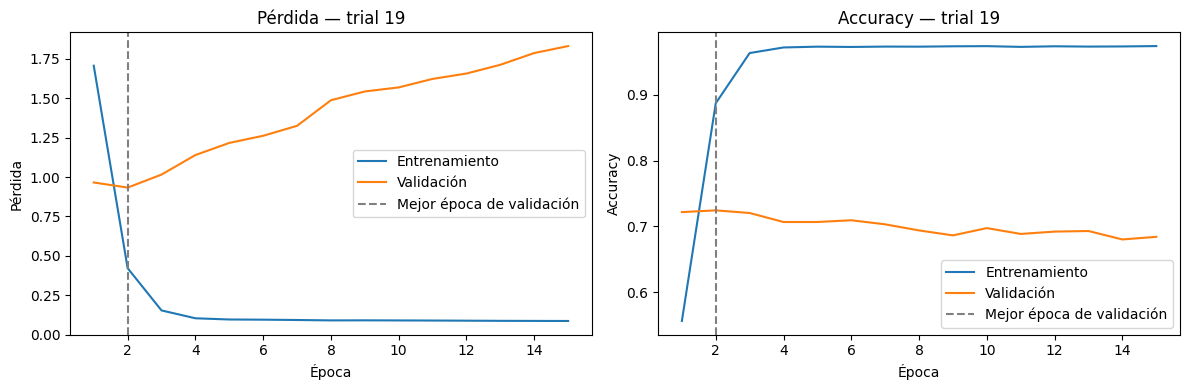

In [ ]:
mejor_trial = estudio_mlp.best_trial
historial_mejor = mejor_trial.user_attrs["historial"]
epocas = range(1, len(historial_mejor["train_loss"]) + 1)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

for conjunto, etiqueta in [
    ("train", "Entrenamiento"),
    ("val", "Validación")
]:
    ejes[0].plot(
        epocas,
        historial_mejor[f"{conjunto}_loss"],
        label=etiqueta
    )
    ejes[1].plot(
        epocas,
        historial_mejor[f"{conjunto}_acc"],
        label=etiqueta
    )

ejes[0].set_title(f"Pérdida — trial {mejor_trial.number}")
ejes[0].set_ylabel("Pérdida")

ejes[1].set_title(f"Accuracy — trial {mejor_trial.number}")
ejes[1].set_ylabel("Accuracy")

for eje in ejes:
    eje.set_xlabel("Época")
    eje.axvline(
        mejor_trial.user_attrs["mejor_epoca"],
        color="gray",
        linestyle="--",
        label="Mejor época de validación"
    )
    eje.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Selección de pruebas que completaron las 15 épocas
completos = tabla_trials[
    tabla_trials["estado"] == "COMPLETE"
].copy()

# Comparación por optimizador, activación y cantidad de capas
for criterio in ["optimizador", "activacion", "capas"]:
    resumen = completos.groupby(criterio).agg(
        pruebas=("trial", "count"),
        mejor_accuracy=("mejor_val_acc", "max"),
        accuracy_mediana=("mejor_val_acc", "median"),
        tiempo_mediano_s=("tiempo_entrenamiento_s", "median")
    )

    print(f"\nComparación por {criterio}:")
    display(resumen.round(4))


Comparación por optimizador:


,pruebas,mejor_accuracy,accuracy_mediana,tiempo_mediano_s
optimizador,,,,
Adam,5,0.7243,0.6880,18.8456
RMSprop,7,0.7061,0.5471,25.5580
SGD,4,0.6880,0.3378,38.1244



Comparación por activacion:


,pruebas,mejor_accuracy,accuracy_mediana,tiempo_mediano_s
activacion,,,,
relu,9,0.7243,0.6147,28.1989
sigmoid,3,0.5471,0.2877,15.7800
tanh,4,0.6898,0.6880,16.3742



Comparación por capas:


,pruebas,mejor_accuracy,accuracy_mediana,tiempo_mediano_s
capas,,,,
1,7,0.7243,0.6880,46.3044
2,5,0.6898,0.6880,18.8456
3,4,0.6306,0.5318,21.9894


### Análisis de rendimiento y tiempos

Entre las pruebas completas, Adam obtuvo la mayor accuracy máxima de validación (72,43 %) y la mayor mediana de las mejores accuracies de cada entrenamiento (68,80 %). RMSprop alcanzó un máximo de 70,61 %, mientras que SGD alcanzó 68,80 %.

ReLU estuvo presente en la configuración ganadora. Sin embargo, Tanh presentó una mediana de accuracy superior a ReLU (68,80 % frente a 61,47 %). Las configuraciones con Sigmoid obtuvieron resultados inferiores dentro del presupuesto evaluado.

La arquitectura ganadora tuvo una sola capa oculta de 64 neuronas. Agregar profundidad no garantizó una mejora: las configuraciones de tres capas alcanzaron un máximo de 63,06 %.

Las medianas de tiempo de entrenamiento fueron de 18,85 s para Adam, 25,56 s para RMSprop y 38,12 s para SGD. Estos tiempos incluyen entrenamiento, validación y registro de métricas, pero excluyen la preparación de los datos.

Las comparaciones describen las configuraciones exploradas y no permiten aislar el efecto de cada hiperparámetro, porque varios cambiaron simultáneamente. Además, los grupos tienen diferentes cantidades de pruebas y el análisis excluye las pruebas podadas, lo que puede favorecer a las configuraciones que superaron el criterio de pruning.


In [ ]:
import json
from google.colab import files

# Tabla con parámetros, resultados y tiempos de todas las pruebas
estudio_mlp.trials_dataframe().to_csv(
    "busqueda_mlp.csv",
    index=False
)

# Detalles de cada prueba, incluidos los historiales disponibles
respaldo = {
    "mejor_trial": estudio_mlp.best_trial.number,
    "mejor_accuracy": estudio_mlp.best_value,
    "mejores_parametros": estudio_mlp.best_params,
    "trials": [
        {
            "numero": trial.number,
            "estado": trial.state.name,
            "parametros": trial.params,
            "valor": trial.value,
            "resultados_intermedios": dict(trial.intermediate_values),
            "atributos": trial.user_attrs
        }
        for trial in estudio_mlp.trials
    ]
}

with open("respaldo_mlp.json", "w", encoding="utf-8") as archivo:
    json.dump(respaldo, archivo, ensure_ascii=False, indent=2)

# Un solo archivo para descargar
import zipfile

with zipfile.ZipFile("resultados_mlp.zip", "w") as archivo_zip:
    archivo_zip.write("busqueda_mlp.csv")
    archivo_zip.write("respaldo_mlp.json")

files.download("resultados_mlp.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Evaluación final y comparación con Softmax

La configuración y la cantidad de épocas se eligen usando validación. Luego se ajusta TF-IDF con todo el conjunto oficial de entrenamiento y se vuelve a entrenar el modelo antes de evaluar en test.

Softmax utiliza la misma representación y los mismos hiperparámetros del optimizador que el MLP seleccionado; su cantidad de épocas se elige con el mismo split de validación. La comparación no incluye una búsqueda independiente para Softmax.

In [ ]:
# Configuración seleccionada por Optuna
mejores_params = estudio_mlp.best_params
epocas_finales = estudio_mlp.best_trial.user_attrs["mejor_epoca"]

# Preprocesamiento del conjunto completo de entrenamiento
textos_train_final = [
    preprocess_text(
        texto,
        remove_stopwords=mejores_params["remove_stopwords"],
        normalization=mejores_params["normalization"]
    )
    for texto in newsgroups_train.data
]

# Aplicación del mismo preprocesamiento al test
textos_test_final = [
    preprocess_text(
        texto,
        remove_stopwords=mejores_params["remove_stopwords"],
        normalization=mejores_params["normalization"]
    )
    for texto in newsgroups_test.data
]

ngram_final = (
    (1, 1)
    if mejores_params["ngram_range"] == "1gram"
    else (1, 2)
)

# Ajuste del vectorizador solamente con entrenamiento
X_train_final, X_test_final, vectorizador_final = vectorize_data(
    textos_train_final,
    textos_test_final,
    ngram_range=ngram_final,
    max_features=mejores_params["max_features"],
    min_df=mejores_params["min_df"]
)

train_loader_final_mlp = DataLoader(
    to_tensor_dataset(X_train_final, newsgroups_train.target),
    batch_size=mejores_params["batch_size"],
    shuffle=True
)

test_loader_final_mlp = DataLoader(
    to_tensor_dataset(X_test_final, newsgroups_test.target),
    batch_size=mejores_params["batch_size"],
    shuffle=False
)

print("Entrenamiento final:", X_train_final.shape)
print("Test:", X_test_final.shape)
print("Épocas elegidas con validación:", epocas_finales)

Entrenamiento final: (11314, 10000)
Test: (7532, 10000)
Épocas elegidas con validación: 2


In [ ]:
torch.manual_seed(SEED)

# Recuperación de la arquitectura ganadora
capas_finales = tuple(
    mejores_params[f"neuronas_capa_{i + 1}"]
    for i in range(mejores_params["n_capas"])
)

modelo_final_mlp = MLP(
    input_dim=X_train_final.shape[1],
    num_classes=NUM_CLASSES,
    hidden_dims=capas_finales,
    activation=mejores_params["activacion"]
).to(device)

# Reconstrucción del optimizador de la configuración ganadora
optimizador_final = optimizador_desde_parametros(
    modelo_final_mlp, mejores_params
)

criterio = nn.CrossEntropyLoss()

with mlflow.start_run(run_name="mlp_final"):
    mlflow.log_params(mejores_params)
    mlflow.log_param("epocas_finales", epocas_finales)

    if device.type == "cuda":
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    for epoca in range(epocas_finales):
        modelo_final_mlp.train()
        perdida_total = 0.0
        aciertos = 0
        cantidad = 0

        for documentos, etiquetas in train_loader_final_mlp:
            documentos = documentos.to(device)
            etiquetas = etiquetas.to(device)

            optimizador_final.zero_grad()
            logits = modelo_final_mlp(documentos)
            perdida = criterio(logits, etiquetas)
            perdida.backward()
            optimizador_final.step()

            perdida_total += perdida.item() * documentos.size(0)
            aciertos += (
                logits.argmax(dim=1) == etiquetas
            ).sum().item()
            cantidad += documentos.size(0)

        loss_epoca = perdida_total / cantidad
        acc_epoca = aciertos / cantidad

        mlflow.log_metric("train_loss", loss_epoca, step=epoca)
        mlflow.log_metric("train_acc", acc_epoca, step=epoca)

        print(
            f"Época {epoca + 1}/{epocas_finales} — "
            f"loss: {loss_epoca:.4f} — accuracy: {acc_epoca:.4f}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    tiempo_final_mlp = time.perf_counter() - inicio
    mlflow.log_metric("tiempo_entrenamiento_s", tiempo_final_mlp)

print(f"Tiempo de entrenamiento: {tiempo_final_mlp:.2f} segundos")

Época 1/2 — loss: 1.5570 — accuracy: 0.5766
Época 2/2 — loss: 0.4106 — accuracy: 0.8868
Tiempo de entrenamiento: 10.04 segundos


In [ ]:
# Modo evaluación
modelo_final_mlp.eval()

predicciones_mlp = []
etiquetas_test = []

# Evaluación sin calcular gradientes ni modificar los pesos
with torch.no_grad():
    for documentos, etiquetas in test_loader_final_mlp:
        documentos = documentos.to(device)

        logits = modelo_final_mlp(documentos)
        predicciones = logits.argmax(dim=1)

        predicciones_mlp.extend(predicciones.cpu().tolist())
        etiquetas_test.extend(etiquetas.tolist())

accuracy_test_mlp = accuracy_score(
    etiquetas_test,
    predicciones_mlp
)

print(f"Accuracy final en test: {accuracy_test_mlp:.4f}")

print(classification_report(
    etiquetas_test,
    predicciones_mlp,
    target_names=class_names,
    zero_division=0
))

Accuracy final en test: 0.6633
                          precision    recall  f1-score   support

             alt.atheism       0.40      0.62      0.49       319
           comp.graphics       0.62      0.64      0.63       389
 comp.os.ms-windows.misc       0.65      0.55      0.59       394
comp.sys.ibm.pc.hardware       0.57      0.67      0.61       392
   comp.sys.mac.hardware       0.71      0.67      0.69       385
          comp.windows.x       0.77      0.69      0.72       395
            misc.forsale       0.76      0.74      0.75       390
               rec.autos       0.62      0.68      0.65       396
         rec.motorcycles       0.76      0.73      0.74       398
      rec.sport.baseball       0.52      0.86      0.65       397
        rec.sport.hockey       0.88      0.86      0.87       399
               sci.crypt       0.71      0.76      0.73       396
         sci.electronics       0.58      0.55      0.57       393
                 sci.med       0.89      0.6

In [ ]:
from sklearn.metrics import f1_score

metricas_finales_mlp = {
    "modelo": "MLP",
    "accuracy_test": accuracy_test_mlp,
    "f1_macro_test": f1_score(
        etiquetas_test, predicciones_mlp, average="macro"
    ),
    "f1_weighted_test": f1_score(
        etiquetas_test, predicciones_mlp, average="weighted"
    ),
    "epocas": epocas_finales,
    "tiempo_entrenamiento_s": tiempo_final_mlp
}

display(pd.DataFrame([metricas_finales_mlp]).round(4))

,modelo,accuracy_test,f1_macro_test,f1_weighted_test,epocas,tiempo_entrenamiento_s
0,MLP,0.6633,0.6517,0.6622,2,10.0417


In [ ]:
# Preprocesamiento elegido para el MLP, aplicado al split train/validación
train_proc, val_proc = obtener_textos_procesados(
    mejores_params["remove_stopwords"],
    mejores_params["normalization"]
)

X_tr_comparacion, X_val_comparacion, _ = vectorize_data(
    train_proc,
    val_proc,
    ngram_range=ngram_final,
    max_features=mejores_params["max_features"],
    min_df=mejores_params["min_df"]
)

loader_train_softmax = DataLoader(
    to_tensor_dataset(X_tr_comparacion, y_train),
    batch_size=mejores_params["batch_size"],
    shuffle=True
)

loader_val_softmax = DataLoader(
    to_tensor_dataset(X_val_comparacion, y_val),
    batch_size=mejores_params["batch_size"],
    shuffle=False
)

torch.manual_seed(SEED)

modelo_softmax_comparacion = SoftmaxRegression(
    input_dim=X_tr_comparacion.shape[1],
    num_classes=NUM_CLASSES
).to(device)

optimizador_softmax = optimizador_desde_parametros(
    modelo_softmax_comparacion, mejores_params
)

with mlflow.start_run(run_name="softmax_comparacion_validacion"):
    historial_softmax = train_softmax_model(
        model=modelo_softmax_comparacion,
        train_loader=loader_train_softmax,
        val_loader=loader_val_softmax,
        optimizer=optimizador_softmax,
        epochs=15,
        run_name="softmax_comparacion"
    )

epocas_softmax = int(np.argmax(historial_softmax["val_acc"])) + 1

print("Época elegida para Softmax:", epocas_softmax)
print(
    "Mejor accuracy de validación:",
    max(historial_softmax["val_acc"])
)

[softmax_comparacion] Epoch 1/15 - train_loss: 2.4468 train_acc: 0.5107 - val_loss: 1.9749 val_acc: 0.6734
[softmax_comparacion] Epoch 2/15 - train_loss: 1.4460 train_acc: 0.8448 - val_loss: 1.5126 val_acc: 0.7084
[softmax_comparacion] Epoch 3/15 - train_loss: 0.9754 train_acc: 0.8911 - val_loss: 1.2901 val_acc: 0.7203
[softmax_comparacion] Epoch 4/15 - train_loss: 0.7135 train_acc: 0.9181 - val_loss: 1.1661 val_acc: 0.7190
[softmax_comparacion] Epoch 5/15 - train_loss: 0.5492 train_acc: 0.9328 - val_loss: 1.0894 val_acc: 0.7172
[softmax_comparacion] Epoch 6/15 - train_loss: 0.4371 train_acc: 0.9461 - val_loss: 1.0403 val_acc: 0.7190
[softmax_comparacion] Epoch 7/15 - train_loss: 0.3574 train_acc: 0.9544 - val_loss: 1.0085 val_acc: 0.7172
[softmax_comparacion] Epoch 8/15 - train_loss: 0.2981 train_acc: 0.9601 - val_loss: 0.9890 val_acc: 0.7150
[softmax_comparacion] Epoch 9/15 - train_loss: 0.2533 train_acc: 0.9638 - val_loss: 0.9764 val_acc: 0.7181
[softmax_comparacion] Epoch 10/15 - t

In [ ]:
torch.manual_seed(SEED)

modelo_final_softmax = SoftmaxRegression(
    input_dim=X_train_final.shape[1],
    num_classes=NUM_CLASSES
).to(device)

optimizador_final_softmax = optimizador_desde_parametros(
    modelo_final_softmax, mejores_params
)

criterio = nn.CrossEntropyLoss()

with mlflow.start_run(run_name="softmax_final_comparacion"):
    mlflow.log_param("epocas_finales", epocas_softmax)

    if device.type == "cuda":
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    for epoca in range(epocas_softmax):
        modelo_final_softmax.train()
        perdida_total = 0.0
        aciertos = 0
        cantidad = 0

        for documentos, etiquetas in train_loader_final_mlp:
            documentos = documentos.to(device)
            etiquetas = etiquetas.to(device)

            optimizador_final_softmax.zero_grad()
            logits = modelo_final_softmax(documentos)
            perdida = criterio(logits, etiquetas)
            perdida.backward()
            optimizador_final_softmax.step()

            perdida_total += perdida.item() * documentos.size(0)
            aciertos += (
                logits.argmax(dim=1) == etiquetas
            ).sum().item()
            cantidad += documentos.size(0)

        mlflow.log_metric(
            "train_loss", perdida_total / cantidad, step=epoca
        )
        mlflow.log_metric(
            "train_acc", aciertos / cantidad, step=epoca
        )

        print(
            f"Época {epoca + 1}/{epocas_softmax} — "
            f"accuracy: {aciertos / cantidad:.4f}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    tiempo_final_softmax = time.perf_counter() - inicio
    mlflow.log_metric("tiempo_entrenamiento_s", tiempo_final_softmax)

    # Evaluación una vez terminado el entrenamiento
    modelo_final_softmax.eval()
    predicciones_softmax = []

    with torch.no_grad():
        for documentos, etiquetas in test_loader_final_mlp:
            logits = modelo_final_softmax(documentos.to(device))
            predicciones_softmax.extend(
                logits.argmax(dim=1).cpu().tolist()
            )

    metricas_finales_softmax = {
        "modelo": "Softmax",
        "accuracy_test": accuracy_score(
            etiquetas_test, predicciones_softmax
        ),
        "f1_macro_test": f1_score(
            etiquetas_test, predicciones_softmax, average="macro"
        ),
        "f1_weighted_test": f1_score(
            etiquetas_test, predicciones_softmax, average="weighted"
        ),
        "epocas": epocas_softmax,
        "tiempo_entrenamiento_s": tiempo_final_softmax
    }

    for metrica in ["accuracy_test", "f1_macro_test", "f1_weighted_test"]:
        mlflow.log_metric(metrica, metricas_finales_softmax[metrica])

comparacion_final = pd.DataFrame([
    metricas_finales_mlp,
    metricas_finales_softmax
])

display(comparacion_final.round(4))

Época 1/3 — accuracy: 0.5614
Época 2/3 — accuracy: 0.8383
Época 3/3 — accuracy: 0.8841


,modelo,accuracy_test,f1_macro_test,f1_weighted_test,epocas,tiempo_entrenamiento_s
0,MLP,0.6633,0.6517,0.6622,2,10.0417
1,Softmax,0.6662,0.6530,0.6638,3,5.8773


### Comparación final y conclusiones

La búsqueda de hiperparámetros incluyó 20 pruebas, con arquitecturas de una, dos y tres capas ocultas, diferentes cantidades de neuronas, activaciones ReLU, Tanh y Sigmoid, y optimizadores Adam, RMSprop y SGD. También se exploraron parámetros de momentos, learning rate, batch size, weight decay y los hiperparámetros de preprocesamiento del trabajo anterior. De las 20 pruebas, 16 finalizaron y 4 fueron interrumpidas mediante pruning.

El MLP seleccionado por Optuna tuvo una capa oculta de 64 neuronas, activación ReLU y optimizador Adam. Alcanzó una accuracy máxima de validación de 72,43 % en la segunda época. Al continuar hasta la época 15, la accuracy de entrenamiento llegó a 97,39 %, mientras que la de validación disminuyó a 68,40 % y su pérdida aumentó. Este comportamiento permitió identificar una configuración con sobreajuste.

Para la evaluación final, el MLP se volvió a entrenar sobre el conjunto completo de entrenamiento durante las dos épocas elegidas mediante validación. Obtuvo 66,33 % de accuracy y un F1 macro de 0,6517 en test, con un tiempo de entrenamiento de 10,04 segundos.

La regresión Softmax se evaluó usando los mismos datos, representación TF-IDF y configuración del optimizador. Su duración se seleccionó mediante validación, resultando en tres épocas. Alcanzó 66,62 % de accuracy y un F1 macro de 0,6530 en test, con un tiempo de 5,88 segundos.

En esta comparación, el MLP seleccionado por Optuna no mostró ventaja frente a Softmax y requirió más tiempo de entrenamiento. La diferencia de accuracy fue pequeña, de 0,29 puntos porcentuales a favor de Softmax. Los resultados muestran que aumentar la complejidad del modelo no garantiza una mejor generalización.

El experimento controlado adicional de la sección 10 mostró sobreajuste en las tres arquitecturas. La configuración de tres capas de 256 neuronas presentó la mayor brecha final entre entrenamiento y validación: 37,96 puntos porcentuales. En las condiciones evaluadas, aumentar el ancho o la profundidad incrementó el costo de entrenamiento sin mejorar el máximo de accuracy de validación.

La configuración de una capa de 64 neuronas del experimento adicional alcanzó 74,11 % de accuracy de validación, superando el 72,43 % del trial seleccionado por Optuna. Por lo tanto, la comparación en test presentada corresponde al modelo seleccionado por esa búsqueda y no permite afirmar que sea el mejor MLP posible. Ese modelo no mostró ventaja frente a Softmax en la evaluación realizada.

Estas conclusiones se limitan a las configuraciones y al presupuesto explorados. Softmax utilizó la configuración de preprocesamiento y optimización seleccionada para el MLP, sin una búsqueda independiente en esta comparación. Además, se realizó una sola ejecución final por modelo y los tiempos corresponden al entorno utilizado en Colab.

Los parámetros de momentos se incluyeron en la búsqueda, pero el número de pruebas por optimizador y la variación simultánea de otros hiperparámetros no permiten aislar sus efectos. Las diferencias de tiempos entre grupos describen las configuraciones evaluadas y no pueden atribuirse únicamente al optimizador. Además, elegir el máximo de validación entre varias configuraciones y épocas puede producir una estimación optimista; por eso se informa por separado el resultado en test.

In [ ]:
comparacion_final.to_csv("comparacion_final.csv", index=False)
tabla_trials.to_csv("resumen_trials.csv", index=False)

with zipfile.ZipFile("resultados_mlp_completos.zip", "w") as archivo_zip:
    archivo_zip.write("busqueda_mlp.csv")
    archivo_zip.write("respaldo_mlp.json")
    archivo_zip.write("comparacion_final.csv")
    archivo_zip.write("resumen_trials.csv")

files.download("resultados_mlp_completos.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Preguntas de reflexión

### Sobre Regresión Softmax (teoría)

**1. ¿Por qué la regresión softmax es una generalización de la regresión logística binaria? ¿Qué pasaría si `NUM_CLASSES = 2`?**

La regresión logística binaria permite clasificar entre dos clases, mientras que la regresión softmax extiende esta idea a múltiples clases. En lugar de calcular un score para una sola clase frente a otra, la regresión softmax calcula un logit para cada una de las clases y luego permite obtener la clase con mayor probabilidad.

Si `NUM_CLASSES = 2`, el modelo seguiría funcionando como una clasificación binaria, utilizando dos logits. Conceptualmente, sería equivalente a una regresión logística binaria.

---

**2. ¿Por qué `CrossEntropyLoss` en PyTorch no necesita que se le aplique `softmax` antes en el forward? ¿Qué pasaría si igual lo aplicaran (softmax + CrossEntropyLoss)?**

`CrossEntropyLoss` recibe directamente los logits del modelo y realiza internamente una operación equivalente a `log_softmax` seguida de la función de pérdida correspondiente.

Por eso, en este TP el `forward` devuelve los logits directamente y no aplica `softmax`.

Si se aplicara `softmax` antes de `CrossEntropyLoss`, esta función interpretaría las probabilidades como si fueran logits y volvería a transformarlas internamente. Esto altera la pérdida y los gradientes respecto de la formulación correcta y puede dificultar el aprendizaje.

---

**3. ¿Qué tipo de frontera de decisión puede aprender un modelo de regresión softmax? ¿Qué limitación tiene frente a un problema que no es linealmente separable?**

La regresión softmax tiene una frontera de decisión lineal, ya que el modelo solamente utiliza una capa lineal y no posee capas ocultas ni funciones de activación no lineales.

Por lo tanto, puede separar las clases mediante fronteras lineales. Si el problema requiere una frontera no lineal para separar correctamente las clases, este modelo tiene una limitación y puede no lograr una buena clasificación.

---

**4. ¿En qué se diferencia este modelo de una red neuronal con capas ocultas? ¿En qué situación elegirían una sobre la otra?**

El modelo Softmax utilizado como referencia tiene solamente una capa lineal. El MLP del presente trabajo agrega capas ocultas con funciones de activación no lineales, por lo que puede aprender relaciones más complejas entre las características de entrada y las clases.

Una red neuronal con capas ocultas puede aprender relaciones no lineales y representaciones más complejas.

La regresión softmax puede ser adecuada cuando se busca un modelo simple, rápido e interpretable. Una red con capas ocultas sería útil cuando las relaciones entre los datos y las clases son más complejas y una separación lineal no resulta suficiente.

---

### Sobre frameworks y herramientas

**5. ¿Qué ventajas y desventajas tiene implementar esto en PyTorch (como hicimos) comparado con usar directamente `sklearn.linear_model.LogisticRegression(multi_class="multinomial")`?**

Una ventaja de PyTorch es que permite tener mayor control sobre la arquitectura del modelo, el entrenamiento, el optimizador, las métricas y el uso de hardware como GPU. Además, el mismo código puede extenderse fácilmente a modelos neuronales más complejos.

Como desventaja, requiere escribir más código y configurar manualmente partes que `scikit-learn` ya resuelve, como el entrenamiento del clasificador y algunos aspectos del manejo de los datos.

En este TP, PyTorch resulta útil porque permite observar de forma explícita el funcionamiento de una regresión softmax y del proceso de entrenamiento.

---

**6. ¿Para qué sirvió específicamente MLflow en este TP? ¿En qué se diferencia de lo que loguea TensorBoard?**

MLflow se utilizó para registrar hiperparámetros, métricas por época y tiempos de entrenamiento. En esta versión no se guardaron los modelos entrenados en MLflow.

TensorBoard permite visualizar curvas durante el entrenamiento. Aunque la función de entrenamiento admite un `writer` opcional, en los experimentos de esta notebook no se creó ni se pasó uno; por lo tanto, no se generaron registros para TensorBoard. Las curvas presentadas se dibujaron con Matplotlib a partir de los historiales guardados.

---

**7. ¿Qué ventaja concreta les dio Optuna frente a probar combinaciones de hiperparámetros a mano?**

Optuna permitió probar automáticamente distintas combinaciones de hiperparámetros y detener algunas pruebas que no prometían buenos resultados. En la búsqueda del MLP se completaron 16 pruebas y se podaron 4, de un total de 20. La mejor obtuvo una accuracy de validación de aproximadamente 0.7243. Así se exploraron más combinaciones sin tener que probarlas todas manualmente.

---

### Sobre el experimento

**8. ¿Qué combinación de preprocesamiento (stopwords, stemming/lematización, n-gramas) encontró Optuna como mejor? ¿Tiene sentido para este dataset?**

La mejor combinación encontrada fue remove_stopwords=False, normalization=none, unigramas, max_features=10000 y min_df=2. El modelo tenía una capa oculta de 64 neuronas con activación ReLU y usaba Adam, con learning rate de aproximadamente 0.00949 y batch size de 64. Obtuvo una accuracy de validación de aproximadamente 0.7243. Es la mejor combinación entre las que se probaron; el resultado no demuestra por sí solo que esa configuración de preprocesamiento sea siempre superior.

---

**9. ¿Qué categorías del dataset presentan mayor dificultad para el modelo según el reporte por categoría? ¿Por qué podría ocurrir, considerando el contenido temático de esas categorías?**


Según el reporte por categoría, el MLP tuvo más dificultad con talk.religion.misc, cuyo recall fue 0.22, y talk.politics.misc, con recall 0.38. Esto significa que el modelo no identificó correctamente muchos ejemplos de esas categorías. Una posible explicación es que compartan vocabulario con otras categorías de religión y política. Para confirmar exactamente con cuáles se confundieron, habría que consultar la matriz de confusión del MLP.

---

**10. ¿Cambiaría su respuesta a la pregunta anterior si usaran un modelo con capas ocultas en vez de regresión softmax? ¿Por qué sí o por qué no?**

En teoría, las capas ocultas permiten aprender relaciones no lineales, pero en este experimento el MLP no obtuvo mejores resultados de test que Softmax: su accuracy fue 0.6633 y su F1 macro 0.6517, frente a 0.6662 y 0.6530 para Softmax. Además, el MLP tardó aproximadamente 10.04 segundos, frente a 5.88 segundos. Por lo tanto, aunque el MLP tiene mayor capacidad, en estas pruebas esa capacidad no produjo una mejora en test. El resultado también depende de la arquitectura, los hiperparámetros y los datos.

## 10. Experimento controlado de sobreajuste

Se comparan distintas arquitecturas manteniendo fijos el preprocesamiento, la activación, el optimizador, el learning rate, el batch size y la cantidad de épocas.

El objetivo es observar si la pérdida de entrenamiento disminuye mientras la pérdida de validación aumenta. No se utiliza el conjunto de test para este experimento.

In [11]:
# Configuración de datos seleccionada anteriormente en el trial 19
config_datos_sobreajuste = {
    "remove_stopwords": False,
    "normalization": "none",
    "ngram_range": (1, 1),
    "max_features": 10000,
    "min_df": 2,
}

textos_train_sobreajuste = [
    preprocess_text(
        texto,
        remove_stopwords=config_datos_sobreajuste["remove_stopwords"],
        normalization=config_datos_sobreajuste["normalization"]
    )
    for texto in textos_train
]

textos_val_sobreajuste = [
    preprocess_text(
        texto,
        remove_stopwords=config_datos_sobreajuste["remove_stopwords"],
        normalization=config_datos_sobreajuste["normalization"]
    )
    for texto in textos_val
]

# Vocabulario e IDF ajustados exclusivamente con train
X_train_sobreajuste, X_val_sobreajuste, vectorizador_sobreajuste = (
    vectorize_data(
        textos_train_sobreajuste,
        textos_val_sobreajuste,
        ngram_range=config_datos_sobreajuste["ngram_range"],
        max_features=config_datos_sobreajuste["max_features"],
        min_df=config_datos_sobreajuste["min_df"]
    )
)

dataset_train_sobreajuste = to_tensor_dataset(
    X_train_sobreajuste, y_train
)
dataset_val_sobreajuste = to_tensor_dataset(
    X_val_sobreajuste, y_val
)

print("Train para sobreajuste:", X_train_sobreajuste.shape)
print("Validación para sobreajuste:", X_val_sobreajuste.shape)
print("Dispositivo:", device)

Train para sobreajuste: (9051, 10000)
Validación para sobreajuste: (2263, 10000)
Dispositivo: cpu


In [12]:
import time
import pandas as pd

arquitecturas_sobreajuste = [
    (64,),
    (256,),
    (256, 256, 256),
]

EPOCAS_SOBREAJUSTE = 25
LR_SOBREAJUSTE = 0.001
BATCH_SOBREAJUSTE = 64

historiales_sobreajuste = {}
resultados_sobreajuste = []

mlflow.set_experiment("mlp_overfit")

try:
    for capas in arquitecturas_sobreajuste:
        torch.manual_seed(SEED)

        # El mismo orden de batches para cada arquitectura
        generador = torch.Generator().manual_seed(SEED)

        loader_train_sobreajuste = DataLoader(
            dataset_train_sobreajuste,
            batch_size=BATCH_SOBREAJUSTE,
            shuffle=True,
            generator=generador
        )

        loader_val_sobreajuste = DataLoader(
            dataset_val_sobreajuste,
            batch_size=BATCH_SOBREAJUSTE,
            shuffle=False
        )

        modelo_sobreajuste = MLP(
            input_dim=X_train_sobreajuste.shape[1],
            num_classes=NUM_CLASSES,
            hidden_dims=capas,
            activation="relu"
        ).to(device)

        optimizador_sobreajuste = optim.Adam(
            modelo_sobreajuste.parameters(),
            lr=LR_SOBREAJUSTE,
            betas=(0.9, 0.999),
            weight_decay=0.0
        )

        cantidad_parametros = sum(
            p.numel() for p in modelo_sobreajuste.parameters()
        )

        nombre = "sobreajuste_" + "x".join(map(str, capas))
        print(f"\nArquitectura: {capas}")
        print(f"Parámetros: {cantidad_parametros:,}")

        with mlflow.start_run(run_name=nombre):
            mlflow.log_params({
                "capas_ocultas": str(capas),
                "n_parametros": cantidad_parametros,
                "activacion": "relu",
                "optimizador": "Adam",
                "learning_rate": LR_SOBREAJUSTE,
                "beta1": 0.9,
                "beta2": 0.999,
                "weight_decay": 0.0,
                "batch_size": BATCH_SOBREAJUSTE,
                "epocas": EPOCAS_SOBREAJUSTE,
                "seed": SEED,
                **config_datos_sobreajuste
            })

            if device.type == "cuda":
                torch.cuda.synchronize()

            inicio = time.perf_counter()

            historial = train_softmax_model(
                model=modelo_sobreajuste,
                train_loader=loader_train_sobreajuste,
                val_loader=loader_val_sobreajuste,
                optimizer=optimizador_sobreajuste,
                epochs=EPOCAS_SOBREAJUSTE,
                run_name=nombre
            )

            if device.type == "cuda":
                torch.cuda.synchronize()

            duracion = time.perf_counter() - inicio
            mlflow.log_metric("tiempo_entrenamiento_s", duracion)

        historiales_sobreajuste[capas] = historial

        resultados_sobreajuste.append({
            "arquitectura": str(capas),
            "parametros": cantidad_parametros,
            "train_acc_final": historial["train_acc"][-1],
            "val_acc_final": historial["val_acc"][-1],
            "brecha_final": (
                historial["train_acc"][-1]
                - historial["val_acc"][-1]
            ),
            "mejor_val_acc": max(historial["val_acc"]),
            "mejor_epoca_val": (
                int(np.argmax(historial["val_acc"])) + 1
            ),
            "min_val_loss": min(historial["val_loss"]),
            "val_loss_final": historial["val_loss"][-1],
            "tiempo_s": duracion,
            "tiempo_por_epoca_s": duracion / EPOCAS_SOBREAJUSTE
        })

        # Respaldo parcial después de terminar cada arquitectura
        pd.DataFrame(resultados_sobreajuste).to_csv(
            "experimento_sobreajuste.csv",
            index=False
        )

finally:
    mlflow.set_experiment("mlp_20newsgroups")

tabla_sobreajuste = pd.DataFrame(resultados_sobreajuste)
display(tabla_sobreajuste.round(4))

2026/10/22 01:44:11 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/22 01:44:12 INFO mlflow.store.db.utils: Updating database tables
2026/10/22 01:44:16 INFO mlflow.tracking.fluent: Experiment with name 'mlp_overfit' does not exist. Creating a new experiment.



Arquitectura: (64,)
Parámetros: 641,364
[sobreajuste_64] Epoch 1/25 - train_loss: 2.8305 train_acc: 0.3433 - val_loss: 2.5199 val_acc: 0.5736
[sobreajuste_64] Epoch 2/25 - train_loss: 2.0509 train_acc: 0.6863 - val_loss: 1.7522 val_acc: 0.6677
[sobreajuste_64] Epoch 3/25 - train_loss: 1.3323 train_acc: 0.7938 - val_loss: 1.3364 val_acc: 0.7084
[sobreajuste_64] Epoch 4/25 - train_loss: 0.9298 train_acc: 0.8440 - val_loss: 1.1393 val_acc: 0.7238
[sobreajuste_64] Epoch 5/25 - train_loss: 0.6908 train_acc: 0.8837 - val_loss: 1.0384 val_acc: 0.7243
[sobreajuste_64] Epoch 6/25 - train_loss: 0.5331 train_acc: 0.9085 - val_loss: 0.9802 val_acc: 0.7344
[sobreajuste_64] Epoch 7/25 - train_loss: 0.4210 train_acc: 0.9318 - val_loss: 0.9480 val_acc: 0.7375
[sobreajuste_64] Epoch 8/25 - train_loss: 0.3392 train_acc: 0.9482 - val_loss: 0.9298 val_acc: 0.7406
[sobreajuste_64] Epoch 9/25 - train_loss: 0.2788 train_acc: 0.9570 - val_loss: 0.9178 val_acc: 0.7411
[sobreajuste_64] Epoch 10/25 - train_loss

2026/10/22 01:50:00 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups' does not exist. Creating a new experiment.


[sobreajuste_256x256x256] Epoch 25/25 - train_loss: 0.0999 train_acc: 0.9708 - val_loss: 3.2190 val_acc: 0.5913


,arquitectura,parametros,train_acc_final,val_acc_final,brecha_final,mejor_val_acc,mejor_epoca_val,min_val_loss,val_loss_final,tiempo_s,tiempo_por_epoca_s
0,"(64,)",641364,0.9741,0.7203,0.2539,0.7411,9,0.9147,1.0169,43.2881,1.7315
1,"(256,)",2565396,0.9741,0.7119,0.2623,0.7353,5,0.9048,1.1215,131.3872,5.2555
2,"(256, 256, 256)",2696980,0.9708,0.5913,0.3796,0.6103,11,1.3534,3.2190,162.4780,6.4991


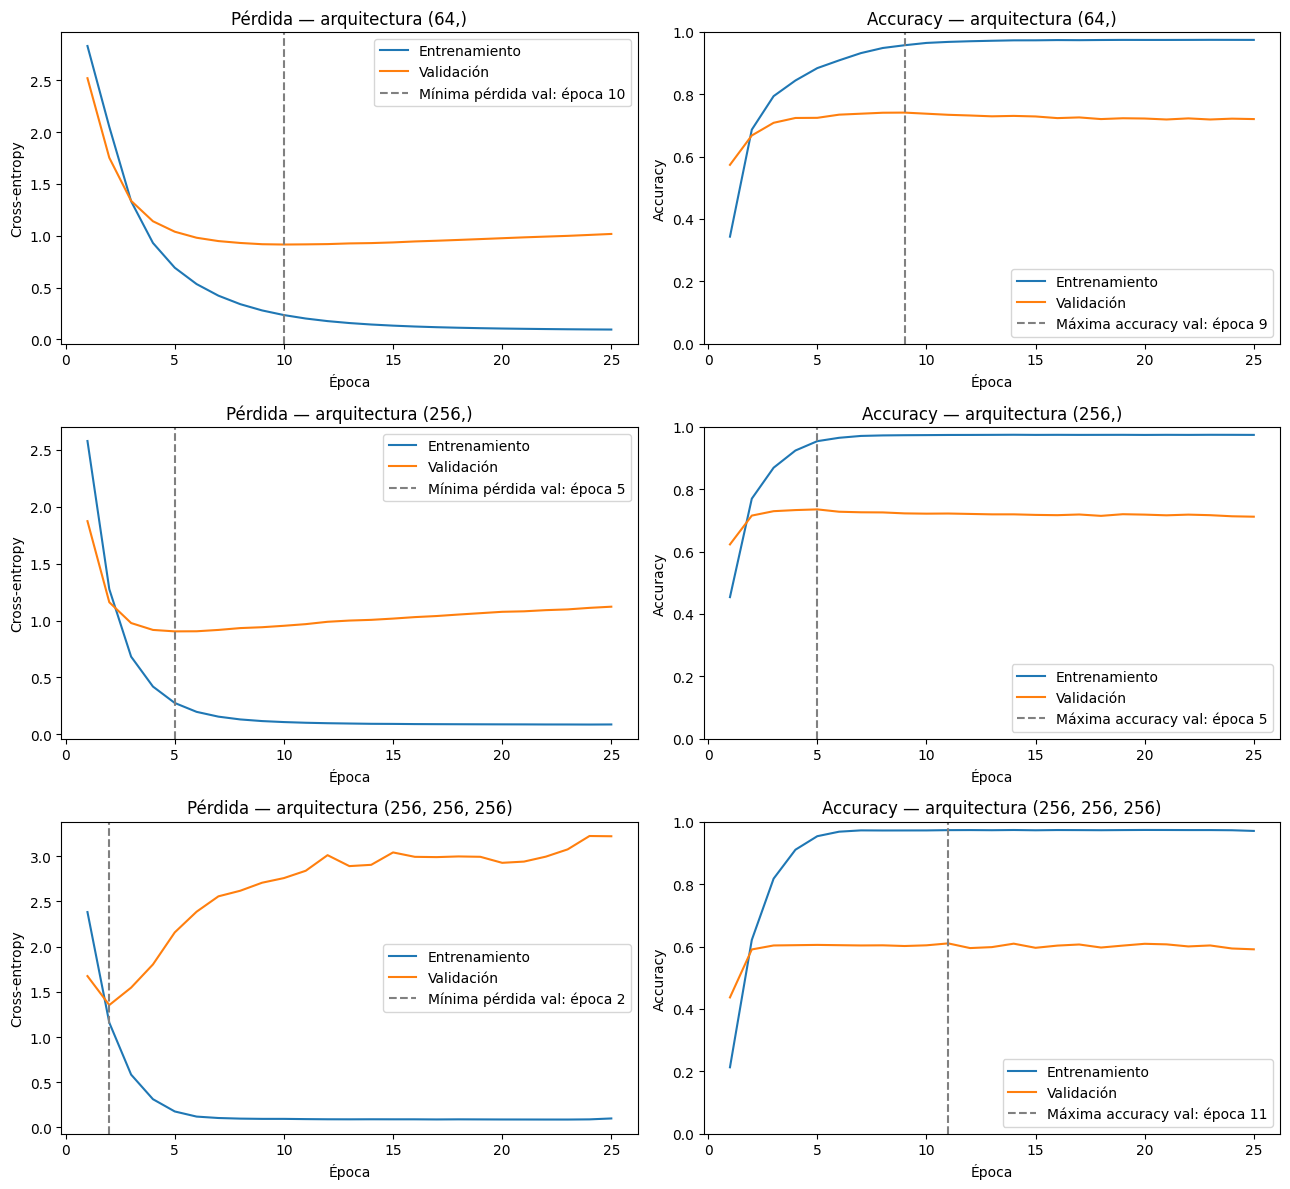

In [14]:
fig, ejes = plt.subplots(
    len(arquitecturas_sobreajuste),
    2,
    figsize=(13, 12)
)

for fila, capas in enumerate(arquitecturas_sobreajuste):
    historial = historiales_sobreajuste[capas]
    epocas = np.arange(1, len(historial["train_loss"]) + 1)

    # Pérdida
    eje_loss = ejes[fila, 0]

    eje_loss.plot(
        epocas, historial["train_loss"],
        label="Entrenamiento"
    )
    eje_loss.plot(
        epocas, historial["val_loss"],
        label="Validación"
    )

    epoca_min_loss = int(np.argmin(historial["val_loss"])) + 1

    eje_loss.axvline(
        epoca_min_loss,
        color="gray",
        linestyle="--",
        label=f"Mínima pérdida val: época {epoca_min_loss}"
    )

    eje_loss.set_title(f"Pérdida — arquitectura {capas}")
    eje_loss.set_xlabel("Época")
    eje_loss.set_ylabel("Cross-entropy")
    eje_loss.legend()

    # Accuracy
    eje_acc = ejes[fila, 1]

    eje_acc.plot(
        epocas, historial["train_acc"],
        label="Entrenamiento"
    )
    eje_acc.plot(
        epocas, historial["val_acc"],
        label="Validación"
    )

    epoca_max_acc = int(np.argmax(historial["val_acc"])) + 1

    eje_acc.axvline(
        epoca_max_acc,
        color="gray",
        linestyle="--",
        label=f"Máxima accuracy val: época {epoca_max_acc}"
    )

    eje_acc.set_title(f"Accuracy — arquitectura {capas}")
    eje_acc.set_xlabel("Época")
    eje_acc.set_ylabel("Accuracy")
    eje_acc.set_ylim(0, 1)
    eje_acc.legend()

plt.tight_layout()
plt.savefig("curvas_sobreajuste.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretación del experimento controlado

Se compararon tres arquitecturas manteniendo fijos los datos, el preprocesamiento, la activación ReLU, Adam con learning rate de 0,001, los parámetros de momentos, el batch size y las 25 épocas de entrenamiento.

Las tres configuraciones mostraron sobreajuste: la pérdida de entrenamiento continuó disminuyendo después de que la pérdida de validación alcanzara su mínimo y comenzara a aumentar. No fue necesario alcanzar un 99 % de accuracy en entrenamiento para observar este comportamiento.

La red de una capa de 64 neuronas alcanzó su mejor accuracy de validación en la época 9, con 74,11 %. Al finalizar, obtuvo 97,41 % en entrenamiento y 72,03 % en validación. Ampliar esa capa a 256 neuronas no mejoró el máximo de validación: alcanzó 73,53 % y terminó con 71,19 %.

La configuración de tres capas de 256 neuronas presentó el sobreajuste más marcado. Su pérdida de validación pasó de un mínimo de 1,3534 en la época 2 a 3,2190 al finalizar, mientras que la pérdida de entrenamiento terminó en 0,0999. La accuracy final fue de 97,08 % en entrenamiento y 59,13 % en validación, con una brecha de 37,96 puntos porcentuales.

Los tiempos totales fueron 43,29 s, 131,39 s y 162,48 s, respectivamente. En estas condiciones, aumentar el ancho y la profundidad incrementó el costo de entrenamiento sin mejorar el máximo de accuracy de validación.

El mínimo de pérdida y el máximo de accuracy de validación pueden ocurrir en épocas diferentes: la pérdida también considera la confianza de las predicciones, mientras que la accuracy solo considera si la clase elegida fue correcta.

Las conclusiones corresponden a una sola semilla y a esta configuración fija de entrenamiento; no demuestran que las redes profundas sean siempre inferiores.

Este experimento adicional tuvo un objetivo diagnóstico. Aunque una de sus configuraciones superó la accuracy de validación del mejor trial de Optuna, no se utilizó para sustituir los modelos de la comparación final ya realizada en test. Por ello, las métricas de test presentadas corresponden al modelo seleccionado por Optuna y a su referencia Softmax.